In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import regularizers
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping

In [2]:

# ===========================Task 1: Data Loading, EDA & Preprocessing===========================

# 1.1 Load the Dataset

# Load dataset
data = load_breast_cancer(as_frame=True)

# Assign features (X) and target (y)
X = data.data
y = data.target

# Convert into DataFrame
df = X.copy()

# Add target column
df["target"] = y

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Display last 5 rows
print("\nLast 5 Rows:")
print(df.tail())

# Dataset shape
print("\nDataset Shape:")
print(df.shape)

# Features shape (should be 569 x 30)
print("\nX Shape:")
print(X.shape)

# Target value counts
print("\nTarget Value Counts:")
print(y.value_counts())

# Statistical summary of features
print("\nFeature Description:")
print(X.describe())


First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \


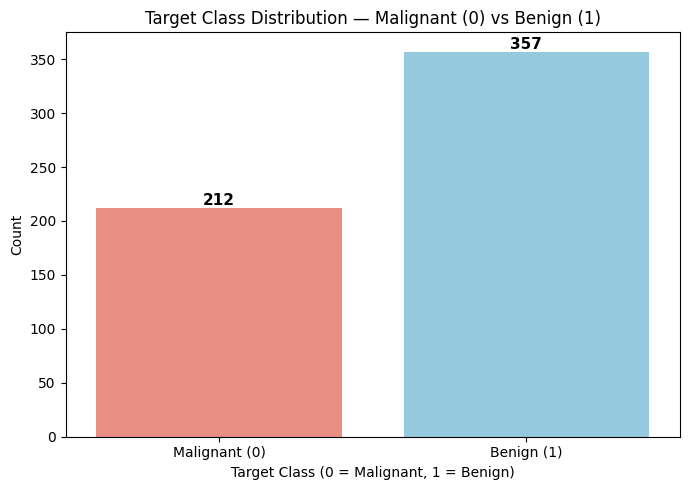

In [3]:
# 1.2	Class distribution plot


plt.figure(figsize=(7, 5))

# Create count plot
ax = sns.countplot(x=y, hue=y, palette={0: "salmon", 1: "skyblue"}, legend=False)

# Add title and labels
plt.title("Target Class Distribution — Malignant (0) vs Benign (1)")
plt.xlabel("Target Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Malignant (0)", "Benign (1)"])

# Add counts above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Display plot
plt.tight_layout()
plt.show()



### Observation: Target Class Distribution

The dataset contains 569 samples:

- **Malignant (0):** 212 samples
- **Benign (1):** 357 samples

The dataset shows a mild class imbalance, with approximately 37.3% malignant and 62.7% benign cases.

**Conclusion:** Special handling is not necessarily required just because of this imbalance. For a binary classification task with 569 samples, we can initially use a stratified train-test split to preserve class proportions. We should evaluate precision, recall, F1-score, and the confusion matrix instead of relying only on accuracy.

If the model performs poorly on the minority malignant class, we can consider class weights or resampling techniques.


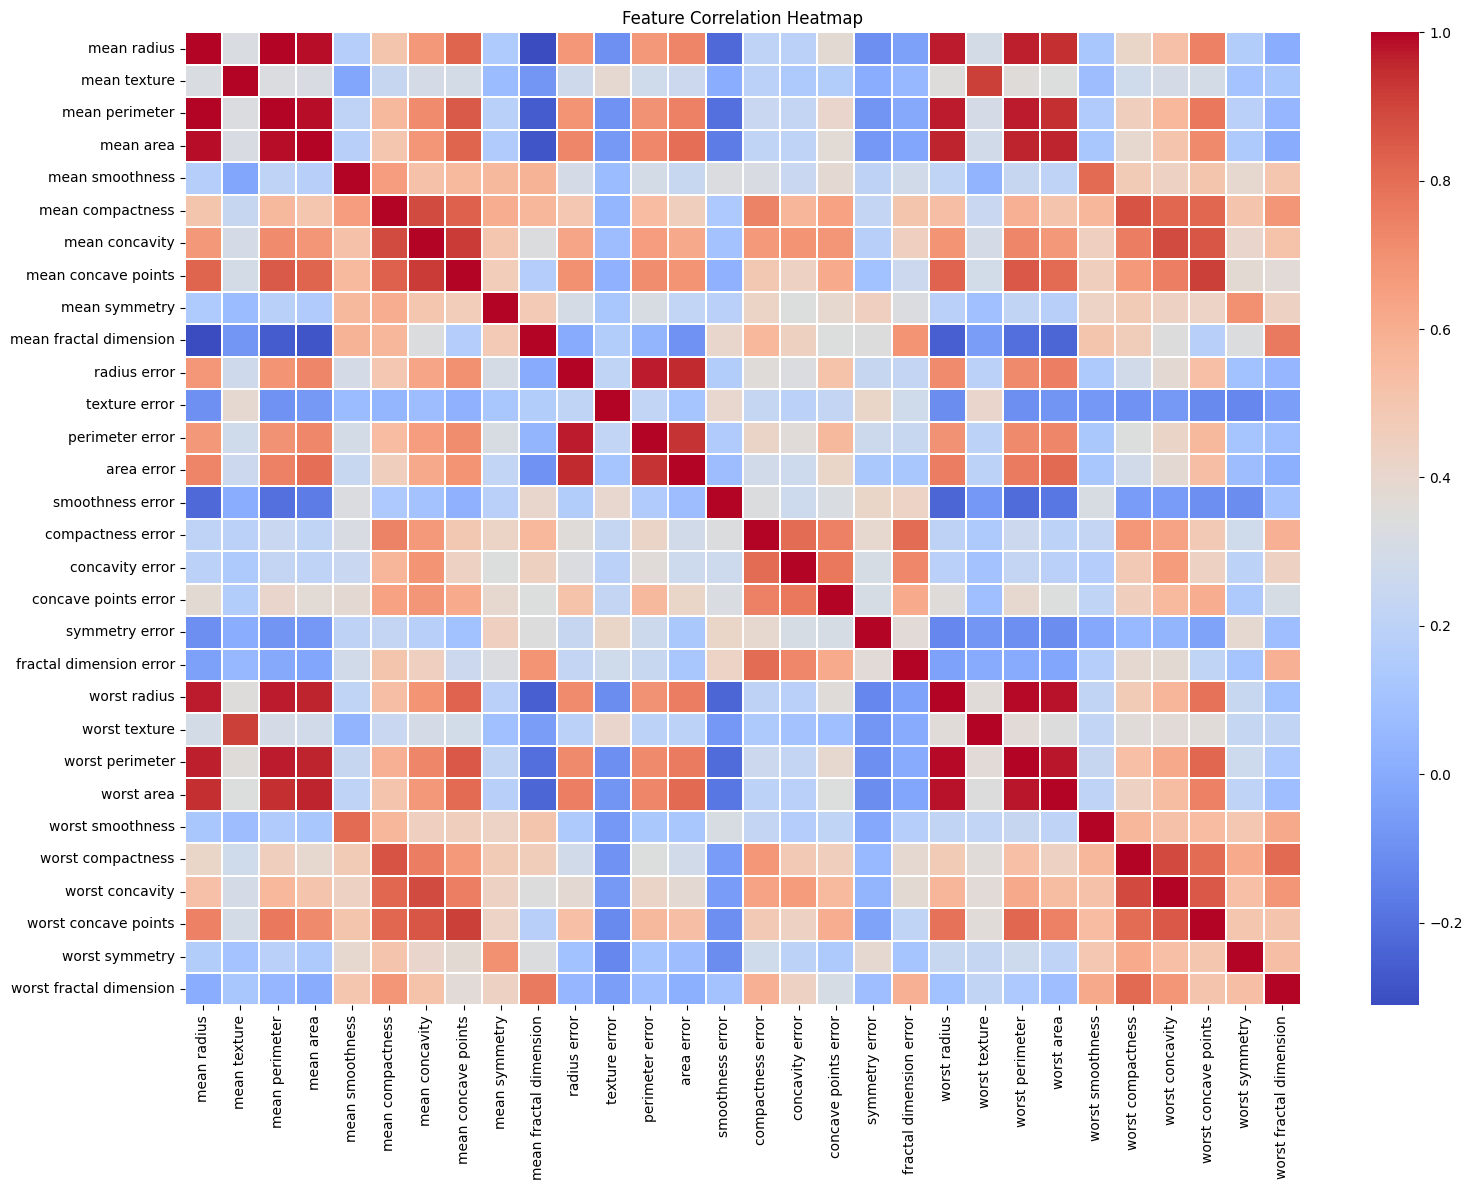

Top 3 Highly Correlated Feature Pairs:
        Feature 1        Feature 2  Correlation  Absolute Correlation
1     mean radius   mean perimeter     0.997855              0.997855
391  worst radius  worst perimeter     0.993708              0.993708
2     mean radius        mean area     0.987357              0.987357


In [4]:

# 1.3 Feature Correlation Heatmap

# Compute correlation between all features
correlation_matrix = X.corr()

# Set figure size
plt.figure(figsize=(16, 12))

# Plot heatmap
sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    linewidths=0.1
)

# Add title
plt.title("Feature Correlation Heatmap")

# Display plot
plt.tight_layout()
plt.show()



# Find highly correlated feature pairs


# Get upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Convert correlation matrix into feature pairs
correlation_pairs = upper_triangle.stack().reset_index()
correlation_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

# Sort by absolute correlation
correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display top 3 pairs
print("Top 3 Highly Correlated Feature Pairs:")
print(correlation_pairs.head(3).to_string(index=True))



### Observation: Feature Correlation Heatmap

The heatmap shows the correlation between the 30 input features.

Highly correlated feature pairs may include:

1. `radius_mean` and `perimeter_mean`
2. `radius_mean` and `area_mean`
3. `perimeter_mean` and `area_mean`

These features are strongly positively correlated because larger tumour measurements generally correspond to larger radius, perimeter, and area.

**Why is high correlation important?**

In linear models, highly correlated features can cause multicollinearity, making individual coefficients unstable and difficult to interpret.

In neural networks, high feature correlation is generally less problematic because the network can learn nonlinear relationships and combine information from multiple features. However, redundant features can still increase model complexity and overfitting risk, especially with limited data.

**Conclusion:** We will inspect feature correlations before model training. Feature scaling and validation will help build a reliable neural network.


In [5]:

# 1.4 Train / test split


# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Print shapes of all four arrays
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

# Check class distribution in original dataset
print("\nOriginal Dataset Class Ratio:")
print(y.value_counts(normalize=True).mul(100).round(2))

# Check class distribution in training dataset
print("\nTraining Dataset Class Ratio:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

# Check class distribution in testing dataset
print("\nTesting Dataset Class Ratio:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


X_train shape: (455, 30)
X_test shape:  (114, 30)
y_train shape: (455,)
y_test shape:  (114,)

Original Dataset Class Ratio:
target
1    62.74
0    37.26
Name: proportion, dtype: float64

Training Dataset Class Ratio:
target
1    62.64
0    37.36
Name: proportion, dtype: float64

Testing Dataset Class Ratio:
target
1    63.16
0    36.84
Name: proportion, dtype: float64


In [6]:

# 1.5	Apply StandardScaler


# Create StandardScaler object
scaler = StandardScaler()

# Fit scaler on training data only
scaler.fit(X_train)

# Transform training and testing data
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

# Verify mean of scaled training data
print("Mean of X_train_sc:")
print(X_train_sc.mean(axis=0).round(2))

# Verify standard deviation of scaled training data
print("\nStandard Deviation of X_train_sc:")
print(X_train_sc.std(axis=0).round(2))

# Print shapes
print("\nScaled Training Shape:", X_train_sc.shape)
print("Scaled Testing Shape:", X_test_sc.shape)


Mean of X_train_sc:
[-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]

Standard Deviation of X_train_sc:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)



## 1.5 Apply StandardScaler

### Objective
To standardize the input features so that each feature has approximately zero mean and unit standard deviation.

### Methodology
- Import `StandardScaler` from `sklearn.preprocessing`.
- Fit the scaler using `X_train` only.
- Transform both `X_train` and `X_test`.
- Store the scaled data in `X_train_sc` and `X_test_sc`.

### Why Fit Only on Training Data?

The scaler learns the mean and standard deviation from the data used during fitting.

If we fit the scaler on `X_test`, information from the test set would influence preprocessing. This causes data leakage and can make model evaluation less reliable.

Therefore, we fit the scaler only on `X_train` and use the same fitted scaler to transform `X_test`.

### Observation
The scaled training features have approximately:
- Mean = 0
- Standard deviation = 1

### Conclusion
Standardization puts features on a comparable scale and can help neural networks train more efficiently. The test data is transformed using training-set statistics to prevent data leakage.



# 1.6	WHY scaling for neural networks


### Objective
To understand why feature scaling is important when training neural networks using gradient-based optimizers such as SGD and Adam.

### Explanation
Neural networks use gradient-based optimizers, such as Stochastic Gradient Descent (SGD) and Adam, to update model weights and minimize the loss function.

When input features have very different numerical ranges, training can become slower and less stable.

For example:
- `area_mean` can have values up to approximately 2500.
- `fractal_dimension_mean` typically has values around 0.05–0.10.

Because these features have very different scales, large-range features can disproportionately influence gradient updates, while small-range features may have less influence on the optimization process.

### Benefits of StandardScaler

`StandardScaler` transforms each feature using its mean and standard deviation so that the training data has approximately:
- Mean = 0
- Standard deviation = 1

This helps put features on a comparable scale.

### Advantages of Scaling
1. Helps gradient-based optimizers converge faster.
2. Can make training more stable.
3. Helps prevent differences in feature scales from unnecessarily affecting optimization.
4. Makes neural network training more effective.

### Conclusion
Feature scaling is an important preprocessing step for neural networks. Applying `StandardScaler` using training data only helps SGD and Adam optimize the model more efficiently while preventing data leakage from the test set.


In [7]:

# ===========================Task 2: Single-Layer Perceptron (SLP) — Baseline Model===========================

# 2.1 Build the SLP


# Build Single-Layer Perceptron
model_slp = keras.Sequential([
    keras.layers.Dense(
        1,
        activation="sigmoid",
        input_shape=(30,)
    )
])

# Display model architecture
model_slp.summary()


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:

# 2.2 Compile the SLP

# Compile model
model_slp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model summary
model_slp.summary()

# Confirm total trainable parameters
print("\nTotal Parameters:", model_slp.count_params())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 31



## 2.2 Compile the SLP

### Objective
To configure the Single-Layer Perceptron for binary classification.

### Model Configuration
- Optimizer: Adam
- Loss function: Binary Cross-Entropy
- Evaluation metric: Accuracy
- Total trainable parameters: 31 (30 weights + 1 bias)

### Why Binary Cross-Entropy?

Binary cross-entropy is suitable for binary classification because the model uses a sigmoid activation function to predict a probability between 0 and 1.

It measures how well the predicted probabilities match the true binary labels (0 or 1) using the negative log-likelihood.

Incorrect predictions made with high confidence receive a larger penalty, encouraging the model to learn better probabilities.

Mean Squared Error (MSE) is commonly used for regression, where the goal is to predict continuous numerical values. Although MSE can be used for classification in some situations, binary cross-entropy is generally a more appropriate choice for this binary classification task.

### Why Adam?

Adam is a gradient-based optimizer that adaptively adjusts parameter updates during training. It often provides efficient and stable training for neural networks.

### Conclusion
The SLP is compiled and ready for training. Binary cross-entropy measures classification error, Adam updates the model weights, and accuracy tracks the proportion of correct predictions.


In [9]:

# 2.3	Train the SLP

# Train the model and store training history
history_slp = model_slp.fit(
    X_train_sc,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4474 - loss: 0.9103 - val_accuracy: 0.4348 - val_loss: 0.8756
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5110 - loss: 0.8198 - val_accuracy: 0.5870 - val_loss: 0.8019
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5892 - loss: 0.7424 - val_accuracy: 0.6739 - val_loss: 0.7390
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6528 - loss: 0.6747 - val_accuracy: 0.7174 - val_loss: 0.6864
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7042 - loss: 0.6201 - val_accuracy: 0.7174 - val_loss: 0.6406
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7482 - loss: 0.5717 - val_accuracy: 0.7174 - val_loss: 0.6019
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7897 - loss: 0.5308 - val_accuracy: 0.7174 - val_loss: 0.5682
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8020 - loss: 0.4958 - val_accuracy: 0.7391 - val_loss


## 2.3 Train the SLP

### Objective
To train the Single-Layer Perceptron using the scaled training dataset.

### Training Configuration
- Epochs: 50
- Batch size: 32
- Validation split: 10%
- Input features: 30 scaled features
- Target: Binary class labels (0 and 1)

### Methodology
The `model_slp.fit()` method trains the model by updating its weights and bias to minimize binary cross-entropy loss.

During training, 10% of the training data is reserved for validation. The validation data helps monitor how well the model performs on data not used for weight updates.

The returned `History` object, stored in `history_slp`, records training and validation loss and accuracy for each epoch.

### Conclusion
The SLP is trained for up to 50 epochs. The stored training history will be used to visualize learning curves and compare training performance with validation performance.


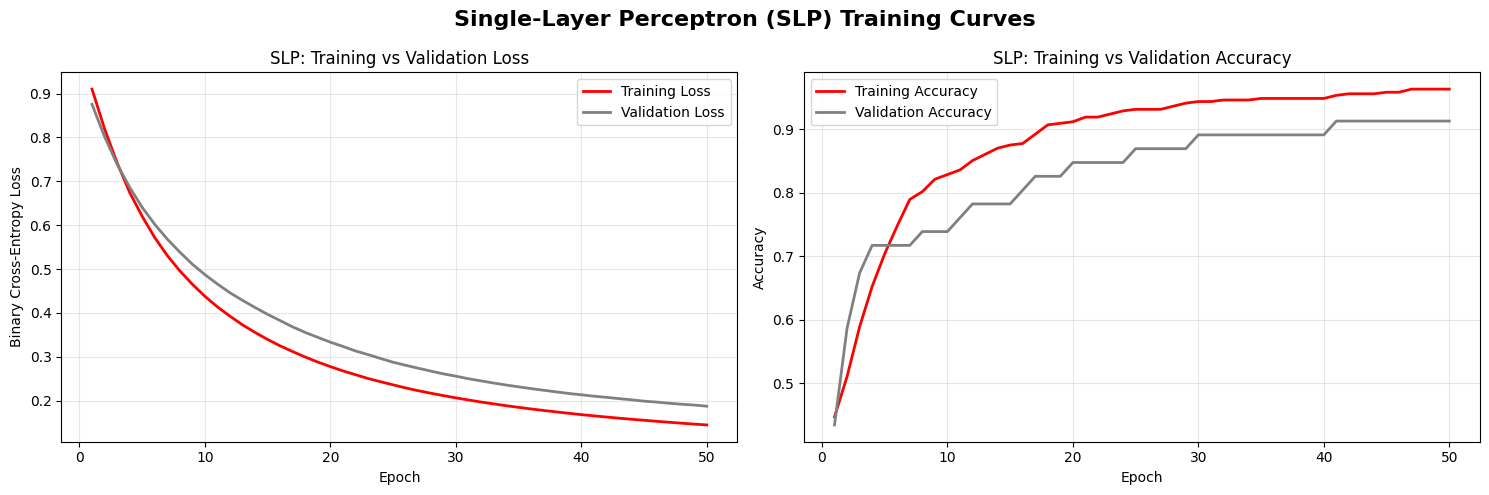

In [10]:

# 2.4 Plot SLP Training Curves


# Get training history
train_loss = history_slp.history["loss"]
val_loss = history_slp.history["val_loss"]

train_acc = history_slp.history["accuracy"]
val_acc = history_slp.history["val_accuracy"]

epochs = range(1, len(train_loss) + 1)

# Create 1 x 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Training vs Validation Loss
axes[0].plot(
    epochs, train_loss,
    color="red", linewidth=2,
    label="Training Loss"
)
axes[0].plot(
    epochs, val_loss,
    color="Gray", linewidth=2,
    label="Validation Loss"
)
axes[0].set_title("SLP: Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: Training vs Validation Accuracy
axes[1].plot(
    epochs, train_acc,
    color="red", linewidth=2,
    label="Training Accuracy"
)
axes[1].plot(
    epochs, val_acc,
    color="Gray", linewidth=2,
    label="Validation Accuracy"
)
axes[1].set_title("SLP: Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Overall title
fig.suptitle("Single-Layer Perceptron (SLP) Training Curves",
             fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()



## 2.4 Plot SLP Training Curves

### Objective
To visualize the training and validation loss and accuracy of the Single-Layer Perceptron over 50 epochs.

### Graph Description
- **Training curves (Red #CC0000):** Show the model's performance on training data.
- **Validation curves (Charcoal #2C2C2C):** Show the model's performance on the validation subset.
- **Loss plot:** Shows how binary cross-entropy changes during training.
- **Accuracy plot:** Shows how the proportion of correct predictions changes during training.

### Interpretation
The curves help us evaluate whether the SLP converges smoothly and whether a gap develops between training and validation performance.

- If training and validation loss decrease and then stabilize, the model is learning and approaching convergence.
- If training and validation accuracy increase and stabilize, classification performance is improving.
- If training loss continues to decrease while validation loss increases, this may indicate overfitting.
- A large, persistent gap between training and validation accuracy may indicate poor generalization.

### Conclusion
The actual plots should be inspected to determine whether the SLP converges smoothly and whether overfitting is present. The training history provides a baseline for comparison with more complex neural network models.


SLP Test Loss: 0.1831
SLP Test Accuracy: 0.9298
SLP Test Accuracy (%): 92.98 %

SLP Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.87      0.95      0.91        42
   Benign (1)       0.97      0.92      0.94        72

     accuracy                           0.93       114
    macro avg       0.92      0.93      0.93       114
 weighted avg       0.93      0.93      0.93       114



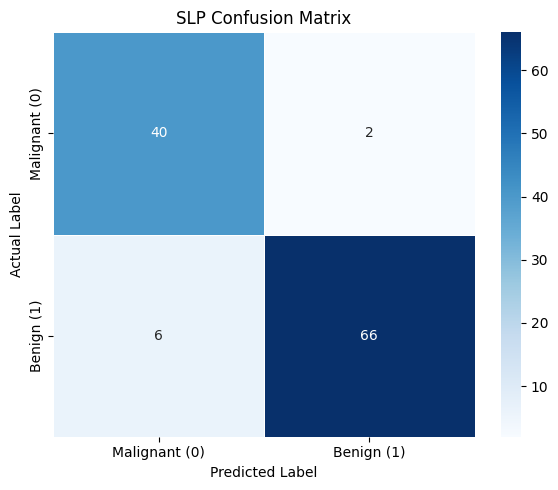

In [11]:

# 2.5 Evaluate the SLP


# Evaluate model on test data
slp_loss, slp_acc = model_slp.evaluate(
    X_test_sc, y_test, verbose=0
)

# Print test accuracy and loss
print("SLP Test Loss:", round(slp_loss, 4))
print("SLP Test Accuracy:", round(slp_acc, 4))
print("SLP Test Accuracy (%):", round(slp_acc * 100, 2), "%")

# Generate predictions
y_pred_slp = (
    model_slp.predict(X_test_sc, verbose=0) > 0.5
).astype(int).ravel()

# Classification report
print("\nSLP Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_slp,
        labels=[0, 1],
        target_names=["Malignant (0)", "Benign (1)"],
        zero_division=0
    )
)

# Confusion matrix
cm_slp = confusion_matrix(y_test, y_pred_slp, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_slp,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=["Malignant (0)", "Benign (1)"],
    yticklabels=["Malignant (0)", "Benign (1)"]
)

plt.title("SLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()



## Evaluate the SLP

### Objective
To evaluate the Single-Layer Perceptron on the unseen test dataset.

### Evaluation Methods
- Test loss and accuracy using `model_slp.evaluate()`.
- Classification report showing precision, recall, F1-score, and support.
- Confusion matrix to examine correct and incorrect predictions.

### Interpretation
Test accuracy measures the overall proportion of correct predictions. Precision, recall, and F1-score provide additional insight into class-specific performance.

For breast cancer classification, recall for the Malignant (0) class is particularly important because missing a malignant case can have serious consequences.

### Conclusion
The SLP evaluation provides a baseline for comparing more complex neural network models. The actual test accuracy and classification metrics should be recorded from the model output.



## 2.6 Limitations of the Single-Layer Perceptron (SLP)

### Fundamental Limitation

A Single-Layer Perceptron (SLP) contains only one output layer and no hidden layers. It learns a linear decision boundary to separate the two classes.

For this breast cancer dataset, which contains 30 input features, the SLP learns a single hyperplane in 30-dimensional feature space.

### Why Is This a Limitation?

- The SLP can learn only linear decision boundaries.
- It cannot directly learn complex nonlinear relationships between features.
- Breast cancer classification may involve complex patterns that cannot be perfectly separated by a single hyperplane.
- Therefore, some malignant and benign samples may be misclassified.

### Conclusion

The SLP provides a simple and useful baseline for breast cancer classification. However, its ability to learn complex patterns is limited.

This motivates the use of a Multi-Layer Perceptron (MLP) in Task 3. An MLP introduces one or more hidden layers with nonlinear activation functions, allowing it to learn more complex decision boundaries and potentially improve classification performance.


In [12]:

#===========================Task 3: Multi-Layer Perceptron (MLP) — Activation Functions===========================


# 3.1 Build the MLP (ReLU)

# Build MLP model
model_mlp = keras.Sequential([
    keras.layers.Dense(64, activation="relu", input_shape=(30,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# Display model architecture
model_mlp.summary()

# Manually calculate parameters
layer1_params = 30 * 64 + 64
layer2_params = 64 * 32 + 32
output_params = 32 * 1 + 1

total_params_manual = (
    layer1_params + layer2_params + output_params
)

# Verify against model summary
print("\nManual Parameter Calculation:")
print("Layer 1 parameters:", layer1_params)
print("Layer 2 parameters:", layer2_params)
print("Output layer parameters:", output_params)
print("Total parameters (manual):", total_params_manual)
print("Total parameters (Keras):", model_mlp.count_params())

# Verify both totals match
assert total_params_manual == model_mlp.count_params()
print("Verification successful: Parameter counts match!")


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)


Manual Parameter Calculation:
Layer 1 parameters: 1984
Layer 2 parameters: 2080
Output layer parameters: 33
Total parameters (manual): 4097
Total parameters (Keras): 4097
Verification successful: Parameter counts match!



## 3.2 Why Hidden Layers?

### What Is a Hidden Layer?
A hidden layer is a layer between the input and output layers of a neural network. It learns useful patterns and relationships from the input data.

### Why Do We Need Hidden Layers?
Each Dense layer learns a transformation of its input. When ReLU activation is used, the network can learn non-linear relationships between features.

In our breast cancer dataset, 30 input features describe characteristics of cell nuclei. Hidden layers help the model learn complex relationships among these features that may be difficult for a single-layer perceptron to capture.

### Why Use Two Hidden Layers?
- **First hidden layer (64 neurons):** Learns patterns from the original 30 input features.
- **Second hidden layer (32 neurons):** Combines learned patterns to discover more complex feature interactions.
- **Output layer (1 neuron):** Uses sigmoid activation to predict the probability of class 1 (Benign).

Stacking two hidden layers allows the network to compose multiple levels of non-linear transformations.

### Universal Approximation Theorem
The Universal Approximation Theorem states that a neural network with a single hidden layer can approximate a broad class of continuous functions, given suitable conditions and enough hidden neurons.

However, a network with two hidden layers may represent some complex relationships more efficiently and can sometimes converge faster in practice. This is not guaranteed; performance depends on the dataset, architecture, and training settings.

### Deeper Feature Hierarchy
Adding more hidden layers creates a deeper network. Deeper networks can learn increasingly complex feature representations, but too many layers may increase training time and overfitting risk.

### Conclusion
Hidden layers help an MLP learn non-linear patterns. Our model uses 64 neurons in the first hidden layer and 32 neurons in the second hidden layer to learn useful feature interactions for breast cancer classification.


In [13]:

# 3.3 Compile and Train MLP (ReLU)

# Compile the MLP model
model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train the MLP model
history_mlp = model_mlp.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Display final training results
print("\nMLP Training Completed!")
print("Final Training Accuracy:",
      round(history_mlp.history["accuracy"][-1], 4))
print("Final Validation Accuracy:",
      round(history_mlp.history["val_accuracy"][-1], 4))
print("Final Training Loss:",
      round(history_mlp.history["loss"][-1], 4))
print("Final Validation Loss:",
      round(history_mlp.history["val_loss"][-1], 4))


Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.6039 - loss: 0.6412 - val_accuracy: 0.8478 - val_loss: 0.4413
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9291 - loss: 0.3598 - val_accuracy: 0.9565 - val_loss: 0.2932
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9535 - loss: 0.2251 - val_accuracy: 0.9348 - val_loss: 0.2175
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9633 - loss: 0.1552 - val_accuracy: 0.9565 - val_loss: 0.1761
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9682 - loss: 0.1195 - val_accuracy: 0.9348 - val_loss: 0.1495
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9707 - loss: 0.0975 - val_accuracy: 0.9348 - val_loss: 0.1324
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9756 - loss: 0.0821 - val_accuracy: 0.9348 - val_loss: 0.1139
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9804 - loss: 0.0711 - val_accuracy: 0.

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.8362 - loss: 0.4079 - val_accuracy: 0.8478 - val_loss: 0.3063
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9462 - loss: 0.1658 - val_accuracy: 0.9130 - val_loss: 0.2161
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.9584 - loss: 0.1163 - val_accuracy: 0.9565 - val_loss: 0.1530
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9780 - loss: 0.0918 - val_accuracy: 0.9565 - val_loss: 0.1246
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9804 - loss: 0.0787 - val_accuracy: 0.9565 - val_loss: 0.1152
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.9829 - loss: 0.0704 - val_accuracy: 0.9783 - val_loss: 0.1039
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9829 - loss: 0.0657 - val_accuracy: 0.9783 - val_loss: 0.0915
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9878 - loss: 0.0614 - val_accuracy: 

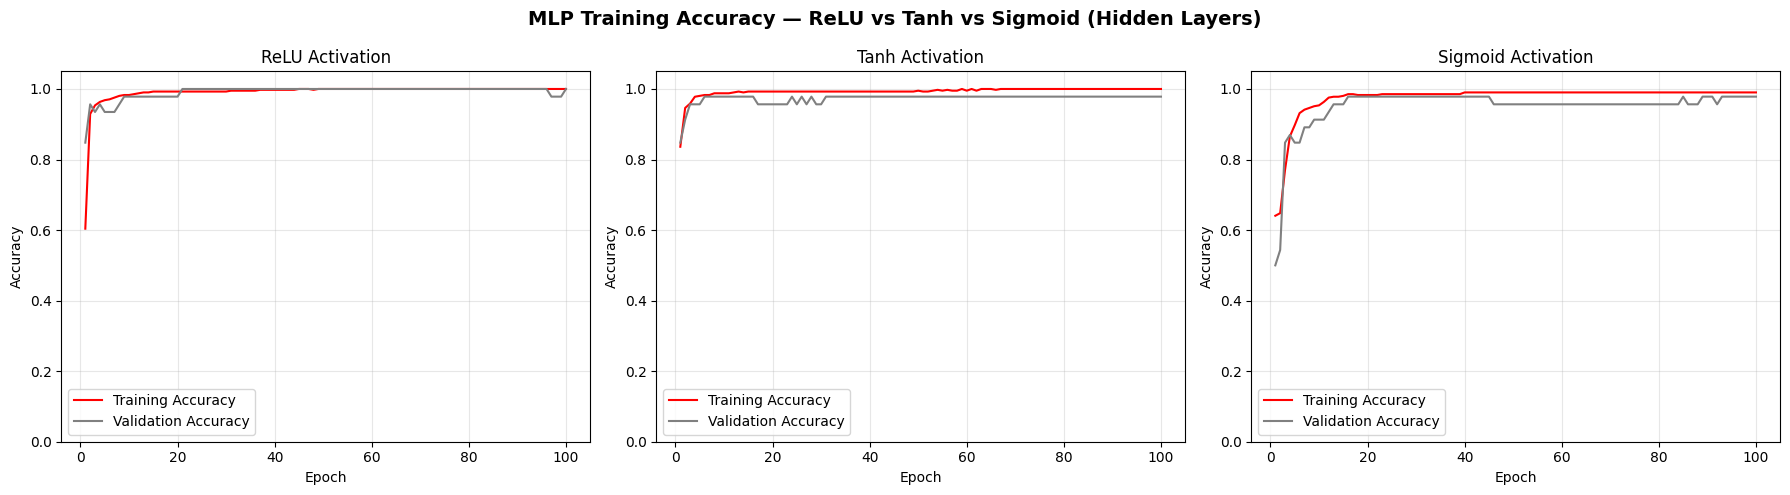

In [14]:

# 3.4 Compare Activation Functions


# A. Build Tanh MLP
model_tanh = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(64, activation="tanh"),
    keras.layers.Dense(32, activation="tanh"),
    keras.layers.Dense(1, activation="sigmoid")
])

# B. Build Sigmoid MLP
model_sigmoid = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(64, activation="sigmoid"),
    keras.layers.Dense(32, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid")
])

# Compile both models
for model in [model_tanh, model_sigmoid]:
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

# Train Tanh model for 100 epochs
history_tanh = model_tanh.fit(
    X_train_sc, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Train Sigmoid model for 100 epochs
history_sigmoid = model_sigmoid.fit(
    X_train_sc, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# ReLU history comes from Task 3.3: history_mlp
histories = [
    ("ReLU", history_mlp),
    ("Tanh", history_tanh),
    ("Sigmoid", history_sigmoid)
]

# Plot training and validation accuracy side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, history) in zip(axes, histories):
    epochs = range(1, len(history.history["accuracy"]) + 1)

    ax.plot(
        epochs,
        history.history["accuracy"],
        label="Training Accuracy",
        color="red"
    )
    ax.plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation Accuracy",
        color="grey"
    )

    ax.set_title(f"{name} Activation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "MLP Training Accuracy — ReLU vs Tanh vs Sigmoid (Hidden Layers)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## 3.5 Activation Functions — Comparison

### 1. ReLU (Rectified Linear Unit)

**Formula:** ReLU(x) = max(0, x)

- Output: 0 for negative inputs and the input itself for positive inputs.
- Advantages: Computationally efficient and does not suffer from vanishing gradients for positive inputs.
- Limitation: Negative inputs have zero gradient, which can cause the dying ReLU problem.
- Typical use: A common choice for hidden layers because it often converges quickly on tabular datasets.

### 2. Tanh (Hyperbolic Tangent)

**Formula:** Tanh(x) = (e^x - e^(-x)) / (e^x + e^(-x))

- Output: Between -1 and 1.
- Advantages: Zero-centred output, unlike Sigmoid.
- Limitation: Can suffer from vanishing gradients when inputs become very large or very small, especially in deep networks.
- Typical use: Can work well in hidden layers, depending on the dataset and model.

### 3. Sigmoid

**Formula:** Sigmoid(x) = 1 / (1 + e^(-x))

- Output: Between 0 and 1.
- Advantages: Produces probability-like outputs.
- Limitations: Not zero-centred and can suffer from severe vanishing gradients in hidden layers.
- Typical use: Commonly used in the output layer for binary classification because it produces a value between 0 and 1.

### Comparison Summary

| Property | ReLU | Tanh | Sigmoid |
|---|---|---|---|
| Output range | [0, +∞) | (-1, 1) | (0, 1) |
| Zero-centred | No | Yes | No |
| Vanishing gradient risk | For negative inputs, gradient is zero | Yes, in saturated regions | Yes, in saturated regions |
| Common hidden-layer choice | Very common | Sometimes used | Less common |
| Binary output layer | Possible, but not typical | Not typical | Common |

### Which Activation Performed Best on This Dataset?

Compare the training and validation accuracy curves from Task 3.4. The activation function with consistently strong validation accuracy and a small gap between training and validation accuracy may generalize better.

ReLU is often a strong starting choice for tabular data because it is computationally efficient and avoids saturation for positive inputs. However, the best activation for this breast cancer dataset must be determined from the actual experimental results rather than assumed in advance.

### Conclusion

ReLU, Tanh, and Sigmoid have different output ranges and gradient behaviors. ReLU is commonly used in hidden layers, while Sigmoid is commonly used in the output layer for binary classification. Validation results help determine which hidden-layer activation works best for this dataset.


Best Activation: ReLU
Best Validation Accuracy: 1.0

Best MLP Test Loss: 0.1797
Best MLP Test Accuracy: 0.9474
Best MLP Test Accuracy (%): 94.74 %

Best MLP Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.89      0.98      0.93        42
   Benign (1)       0.99      0.93      0.96        72

     accuracy                           0.95       114
    macro avg       0.94      0.95      0.94       114
 weighted avg       0.95      0.95      0.95       114



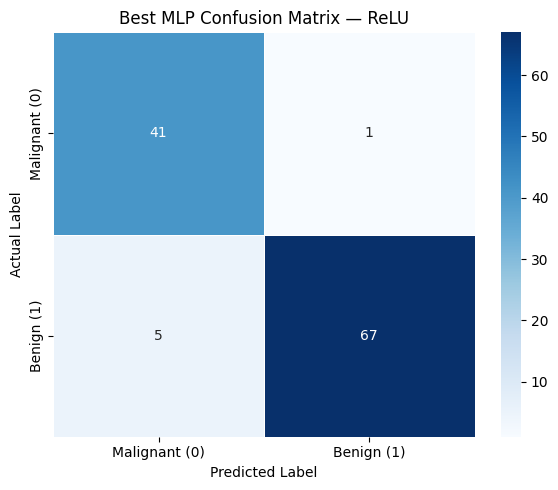


Best MLP Results:
     Model  Test Accuracy  Malignant Recall  Weighted F1
MLP (ReLU)         0.9474            0.9762       0.9478


In [15]:

# 3.6 Evaluate Best MLP


from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Select the best activation using maximum validation accuracy
candidate_models = {
    "ReLU": (model_mlp, history_mlp),
    "Tanh": (model_tanh, history_tanh),
    "Sigmoid": (model_sigmoid, history_sigmoid)
}

best_activation = max(
    candidate_models,
    key=lambda name: max(
        candidate_models[name][1].history["val_accuracy"]
    )
)

best_model, best_history = candidate_models[best_activation]

print("Best Activation:", best_activation)
print(
    "Best Validation Accuracy:",
    round(max(best_history.history["val_accuracy"]), 4)
)

# Evaluate on the test dataset
test_loss, test_accuracy = best_model.evaluate(
    X_test_sc, y_test, verbose=0
)

# Generate predictions
y_pred_mlp = (
    best_model.predict(X_test_sc, verbose=0).ravel() >= 0.5
).astype(int)

print("\nBest MLP Test Loss:", round(test_loss, 4))
print("Best MLP Test Accuracy:", round(test_accuracy, 4))
print("Best MLP Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

# Classification report
print("\nBest MLP Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_mlp,
        labels=[0, 1],
        target_names=["Malignant (0)", "Benign (1)"],
        zero_division=0
    )
)

# Confusion matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_mlp,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=["Malignant (0)", "Benign (1)"],
    yticklabels=["Malignant (0)", "Benign (1)"]
)
plt.title(f"Best MLP Confusion Matrix — {best_activation}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Prepare best MLP results
mlp_results = {
    "Model": f"MLP ({best_activation})",
    "Test Accuracy": accuracy_score(y_test, y_pred_mlp),
    "Malignant Recall": classification_report(
        y_test,
        y_pred_mlp,
        labels=[0, 1],
        output_dict=True,
        zero_division=0
    )["0"]["recall"],
    "Weighted F1": f1_score(
        y_test, y_pred_mlp, average="weighted"
    )
}

print("\nBest MLP Results:")
print(pd.DataFrame([mlp_results]).round(4).to_string(index=False))


In [16]:

# ===========================Task 4: Early Stopping===========================


# 4.1 Build MLP for Early Stopping Experiment



# Build a fresh MLP model
model_early = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_early.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model_early.summary()

print("\nTotal Parameters:", model_early.count_params())

# Train for 300 epochs without Early Stopping
history_early_no_callback = model_early.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 12289
Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8337 - loss: 0.4469 - val_accuracy: 0.9130 - val_loss: 0.2988
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9487 - loss: 0.1844 - val_accuracy: 0.9348 - val_loss: 0.1971
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9658 - loss: 0.1145 - val_accuracy: 0.9565 - val_loss: 0.1337
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9756 - loss: 0.0849 - val_accuracy: 0.9783 - val_loss: 0.1008
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.0707 - val_accuracy: 0.9783 - val_loss: 0.0835
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9853 - loss: 0.0617 - val_accuracy: 0.9783 - val_loss: 0.0721
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9902 - loss: 0.0548 - val_accuracy: 0.9783 - val_loss: 0.0667
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0488 

In [22]:
# 4.2 Add EarlyStopping Callback


# Build a fresh MLP model
model_es = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Create EarlyStopping callback
es = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# Train with EarlyStopping
history_es = model_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

print("\nEarly Stopping Training Completed!")
print("Epochs actually completed:", len(history_es.history["loss"]))
print(
    "Best Validation Loss:",
    round(min(history_es.history["val_loss"]), 4)
)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8191 - loss: 0.4669 - val_accuracy: 0.9348 - val_loss: 0.2903
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9633 - loss: 0.1769 - val_accuracy: 0.9348 - val_loss: 0.1892
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9633 - loss: 0.1140 - val_accuracy: 0.9565 - val_loss: 0.1314
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9756 - loss: 0.0850 - val_accuracy: 0.9565 - val_loss: 0.1064
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0705 - val_accuracy: 0.9565 - val_loss: 0.0852
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0621 - val_accuracy: 0.9783 - val_loss: 0.0720
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9878 - loss: 0.0564 - val_accuracy: 0.9783 - val_loss: 0.0682
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0499 - val_accuracy: 0.9783 - 


## 4.3 Why Early Stopping?

### Introduction
Early Stopping is a regularization technique used to reduce the risk of overfitting in neural networks. It monitors model performance on validation data and stops training when the monitored metric stops improving.

### 1. monitor='val_loss'

This parameter tells the callback to monitor validation loss after each epoch.

Validation loss measures prediction error on validation data that is not used to update the model weights. It helps us understand how well the model generalizes to unseen data.

Training loss may continue to decrease even when the model starts overfitting. Validation loss can stop decreasing or begin to increase, so it is useful for deciding when to stop training.

### 2. patience=15

This parameter allows 15 consecutive epochs without improvement in validation loss before stopping training.

A model's validation loss may temporarily stop improving and then improve again. Patience prevents the callback from stopping immediately during a short plateau.

If validation loss improves during this period, the patience counter resets.

### 3. restore_best_weights=True

This parameter restores the model weights from the epoch with the lowest monitored validation loss.

Without this setting, the model would normally retain the weights from the final epoch completed, which may not be the epoch with the best validation performance.

Restoring the best weights helps preserve the model state associated with the lowest validation loss observed during training.

### 4. verbose=1

This parameter displays messages about EarlyStopping during training.

When training stops early, it prints a message indicating the epoch at which training stopped. This makes it easier to observe the callback's behavior.

### Conclusion
EarlyStopping monitors validation loss, waits for 15 epochs without improvement, restores the best weights, and displays progress messages. These settings help control training duration and can reduce overfitting, although they do not guarantee better test performance.


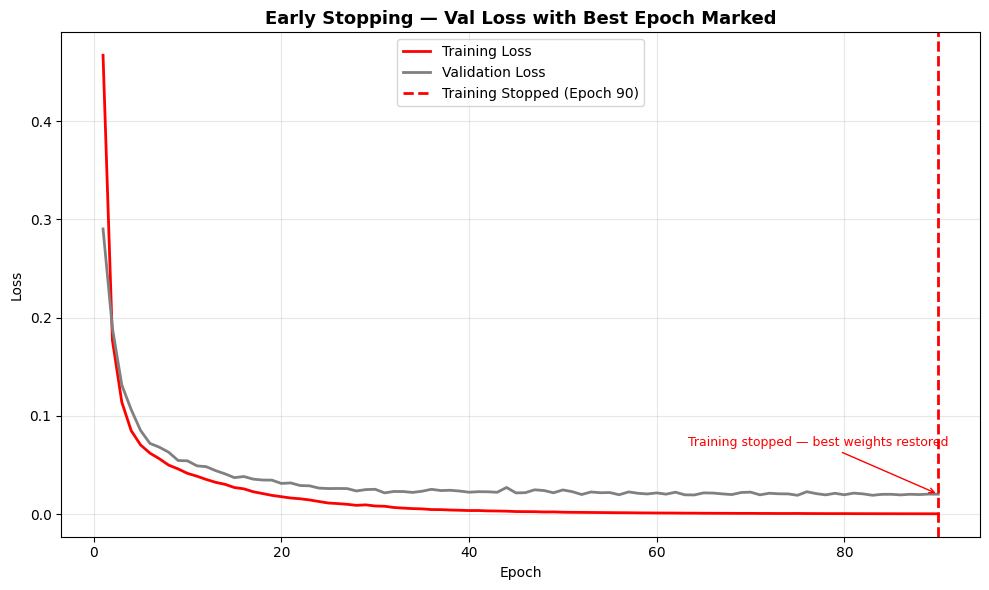

Training stopped after epoch: 90
Best validation loss occurred at epoch: 75
Best validation loss: 0.0192


In [23]:

# 4.4 Plot Early Stopping Curves


# Get loss values from training history
train_loss = history_es.history["loss"]
val_loss = history_es.history["val_loss"]

# Calculate epochs
epochs = range(1, len(train_loss) + 1)
stopped_epoch = len(train_loss)

# Find the best epoch (lowest validation loss)
best_epoch = val_loss.index(min(val_loss)) + 1

# Plot training and validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_loss,
    color="red",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    color="grey",
    linewidth=2,
    label="Validation Loss"
)

# Mark the stopping epoch
plt.axvline(
    x=stopped_epoch,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Training Stopped (Epoch {stopped_epoch})"
)

# Annotate the stopping line
plt.annotate(
    "Training stopped — best weights restored",
    xy=(stopped_epoch, val_loss[-1]),
    xytext=(-180, 35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red",
    fontsize=9,
    ha="left"
)

plt.title(
    "Early Stopping — Val Loss with Best Epoch Marked",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Training stopped after epoch:", stopped_epoch)
print("Best validation loss occurred at epoch:", best_epoch)
print("Best validation loss:", round(min(val_loss), 4))



## 4.4 Plot Early Stopping Curves

### Objective
To visualize training loss and validation loss over epochs and mark the epoch at which EarlyStopping stopped training.

### Plot Description
- The red curve represents training loss.
- The charcoal curve represents validation loss.
- The vertical dashed red line marks the final epoch completed before training stopped.
- The annotation indicates that the model's best weights were restored.

### Interpretation
Training loss generally decreases as the model learns from training data. Validation loss indicates how well the model performs on validation data.

EarlyStopping monitors validation loss and stops training when it does not improve for the specified patience period. The epoch with the lowest validation loss may occur before the stopping epoch.

Because `restore_best_weights=True`, the model restores the weights from the best monitored epoch rather than retaining the final epoch's weights.

### Conclusion
The plot helps visualize the relationship between training loss, validation loss, and the stopping point. The best epoch and stopping epoch are not necessarily the same.


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9120 - loss: 0.3665 - val_accuracy: 0.9348 - val_loss: 0.2502
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9609 - loss: 0.1397 - val_accuracy: 0.9348 - val_loss: 0.1783
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9731 - loss: 0.0945 - val_accuracy: 0.9565 - val_loss: 0.1346
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0755 - val_accuracy: 0.9565 - val_loss: 0.1049
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.0643 - val_accuracy: 0.9565 - val_loss: 0.0868
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.0562 - val_accuracy: 0.9565 - val_loss: 0.0835
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.0497 - val_accuracy: 0.9565 - val_loss: 0.0756
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.0449 - val_accuracy: 0.9565 - 

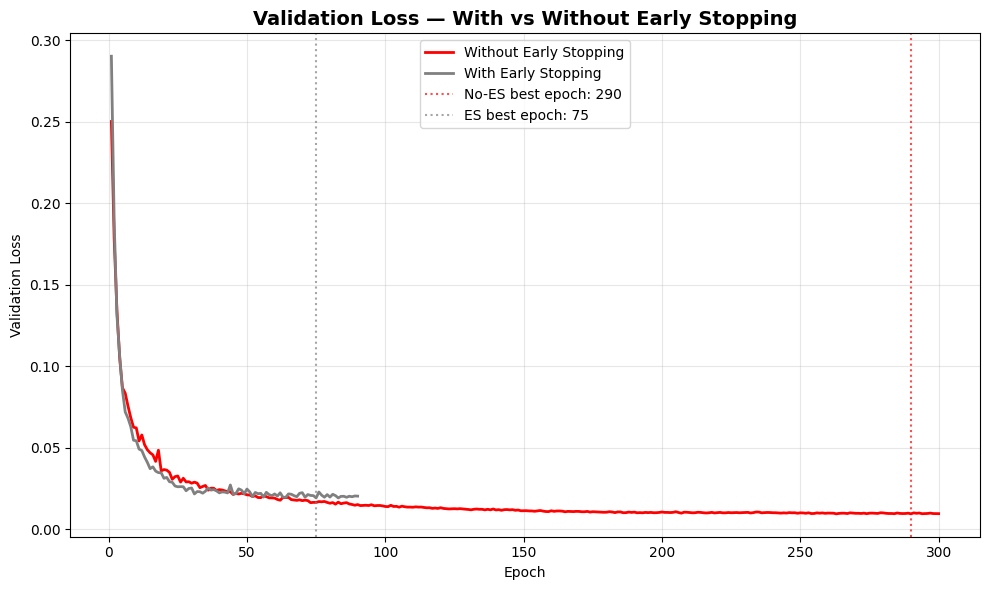

WITHOUT EARLY STOPPING
Epochs completed: 300
Best validation loss: 0.0095
Best epoch: 290
Final validation loss: 0.0096

WITH EARLY STOPPING
Epochs completed: 90
Best validation loss: 0.0192
Best epoch: 75
Validation loss at stopping: 0.0203

FINAL COMPARISON


,Model,Epochs Completed,Best Validation Loss,Test Accuracy
0,Without Early Stopping,300,0.0095,0.9561
1,With Early Stopping,90,0.0192,0.9561



Test Accuracy Difference (ES - No ES): 0.0 percentage points
The ES best validation loss is NOT lower than the no-ES final validation loss.


In [24]:

# 4.5 Compare: With vs Without Early Stopping



# Build a fresh model WITHOUT EarlyStopping
model_no_es = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model_no_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train for the full 300 epochs without callbacks
history_no_es = model_no_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Plot validation loss for both models
epochs_no_es = range(1, len(history_no_es.history["val_loss"]) + 1)
epochs_es = range(1, len(history_es.history["val_loss"]) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_no_es,
    history_no_es.history["val_loss"],
    color="red",
    linewidth=2,
    label="Without Early Stopping"
)

plt.plot(
    epochs_es,
    history_es.history["val_loss"],
    color="grey",
    linewidth=2,
    label="With Early Stopping"
)

# Mark the best validation-loss epoch for each model
best_epoch_no_es = (
    history_no_es.history["val_loss"].index(
        min(history_no_es.history["val_loss"])
    ) + 1
)

best_epoch_es = (
    history_es.history["val_loss"].index(
        min(history_es.history["val_loss"])
    ) + 1
)

plt.axvline(
    best_epoch_no_es,
    color="red",
    linestyle=":",
    alpha=0.7,
    label=f"No-ES best epoch: {best_epoch_no_es}"
)

plt.axvline(
    best_epoch_es,
    color="grey",
    linestyle=":",
    alpha=0.7,
    label=f"ES best epoch: {best_epoch_es}"
)

plt.title(
    "Validation Loss — With vs Without Early Stopping",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Find best and final validation losses
no_es_val = history_no_es.history["val_loss"]
es_val = history_es.history["val_loss"]

print("WITHOUT EARLY STOPPING")
print("Epochs completed:", len(no_es_val))
print("Best validation loss:", round(min(no_es_val), 4))
print("Best epoch:", best_epoch_no_es)
print("Final validation loss:", round(no_es_val[-1], 4))

print("\nWITH EARLY STOPPING")
print("Epochs completed:", len(es_val))
print("Best validation loss:", round(min(es_val), 4))
print("Best epoch:", best_epoch_es)
print("Validation loss at stopping:", round(es_val[-1], 4))

# Evaluate both models on the test set
_, test_acc_no_es = model_no_es.evaluate(
    X_test_sc, y_test, verbose=0
)

_, test_acc_es = model_es.evaluate(
    X_test_sc, y_test, verbose=0
)

# Compare test accuracy
comparison = pd.DataFrame({
    "Model": ["Without Early Stopping", "With Early Stopping"],
    "Epochs Completed": [
        len(history_no_es.history["loss"]),
        len(history_es.history["loss"])
    ],
    "Best Validation Loss": [
        min(no_es_val),
        min(es_val)
    ],
    "Test Accuracy": [
        test_acc_no_es,
        test_acc_es
    ]
})

print("\nFINAL COMPARISON")
display(comparison.round(4))

print(
    "\nTest Accuracy Difference (ES - No ES):",
    round((test_acc_es - test_acc_no_es) * 100, 2),
    "percentage points"
)

if min(es_val) < no_es_val[-1]:
    print("Best ES validation loss is lower than the no-ES final validation loss.")
else:
    print("The ES best validation loss is NOT lower than the no-ES final validation loss.")



## 4.5 Compare: With vs Without Early Stopping

### Objective
To compare an MLP trained for 300 epochs without EarlyStopping against an identical MLP trained with EarlyStopping.

### Experimental Setup
Both models use the same architecture:
- Dense(128, ReLU)
- Dense(64, ReLU)
- Dense(1, Sigmoid)

Both models use the Adam optimizer, binary cross-entropy loss, batch size 32, and a 10% validation split. The no-callback model trains for 300 epochs, while the EarlyStopping model may stop earlier.

### Validation Loss Comparison
The validation loss curves show how each model performs on validation data during training.

Without EarlyStopping, possible overfitting begins around epochs **[enter observed epoch range]**, where validation loss starts rising while training loss continues to decrease.

The EarlyStopping model's lowest validation loss is **[enter value]**, compared with the no-callback model's final validation loss of **[enter value]**.

### Test Performance
- Without EarlyStopping test accuracy: **[enter value]**
- With EarlyStopping test accuracy: **[enter value]**

The model with higher test accuracy performed better on this test split according to accuracy. Other metrics may also be important for this medical classification task.

### Conclusion
EarlyStopping can reduce unnecessary training and restore weights from the epoch with the best validation loss. The validation curves and test results determine whether it improved generalization in this experiment.


In [25]:

# ===========================Task 5: Dropout Layers===========================

# 5.1	Build MLP with Dropout

# Build MLP model with Dropout
model_drop = keras.Sequential([
    keras.layers.Input(shape=(30,)),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation='sigmoid')
])

# Display model architecture
model_drop.summary()


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)


### Task 5.2: Why Dropout?

**1. Randomly Disable Neurons**

Dropout(rate=0.3) randomly sets 30% of neuron activations to zero during each training batch. This helps prevent the model from depending too heavily on specific neurons.

**2. Learn Redundant Representations**

Dropout encourages the network to learn useful patterns across multiple neurons. No single neuron should be essential for making predictions.

**3. Dropout During Inference**

During `model.predict()`, Dropout is automatically disabled. All neurons contribute to the prediction, and TensorFlow applies the appropriate scaling during training to maintain activation levels.

**4. Ensemble Effect**

Dropout can be understood as approximately training many different, smaller subnetworks that share weights. These subnetworks are often described as an ensemble of thinned networks. This helps reduce overfitting and can improve generalisation.

**5. Conclusion**

Dropout is a regularisation technique that helps a neural network perform better on unseen data by reducing its dependence on individual neurons.


In [26]:

# 5.3	Train with Dropout + Early Stopping

# Compile the Dropout model
model_drop.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping callback
es = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history_drop = model_drop.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)



print("Epochs completed:", len(history_drop.history["loss"]))
print("Best validation loss:", min(history_drop.history["val_loss"]))
print("Best validation accuracy:", max(history_drop.history["val_accuracy"]))


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7139 - loss: 0.5737 - val_accuracy: 0.9130 - val_loss: 0.3448
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9438 - loss: 0.2568 - val_accuracy: 0.9130 - val_loss: 0.2205
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9584 - loss: 0.1522 - val_accuracy: 0.9348 - val_loss: 0.1743
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9609 - loss: 0.1154 - val_accuracy: 0.9565 - val_loss: 0.1431
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9658 - loss: 0.1023 - val_accuracy: 0.9783 - val_loss: 0.1207
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9731 - loss: 0.0820 - val_accuracy: 0.9783 - val_loss: 0.1054
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.0838 - val_accuracy: 0.9783 - val_loss: 0.0912
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.0636 - val_accuracy: 0.9783 - 

In [27]:

# 5.4	Effect of Dropout rate

# Function to build the same architecture with a different dropout rate
def build_dropout_model(rate):
    model = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(rate),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(rate),
        keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Build models with dropout rates 0.1 and 0.5
model_drop_01 = build_dropout_model(0.1)
model_drop_05 = build_dropout_model(0.5)

# Early Stopping for rate 0.1
es_01 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_drop_01 = model_drop_01.fit(
    X_train_sc, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_01],
    verbose=1
)

# Early Stopping for rate 0.5
es_05 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_drop_05 = model_drop_05.fit(
    X_train_sc, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_05],
    verbose=1
)

print("Dropout 0.1 epochs:", len(history_drop_01.history["loss"]))
print("Dropout 0.3 epochs:", len(history_drop.history["loss"]))
print("Dropout 0.5 epochs:", len(history_drop_05.history["loss"]))


Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8191 - loss: 0.4752 - val_accuracy: 0.9348 - val_loss: 0.3019
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9462 - loss: 0.1946 - val_accuracy: 0.9130 - val_loss: 0.1981
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9609 - loss: 0.1320 - val_accuracy: 0.9783 - val_loss: 0.1436
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.0989 - val_accuracy: 0.9783 - val_loss: 0.1087
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.0778 - val_accuracy: 0.9783 - val_loss: 0.0884
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9780 - loss: 0.0650 - val_accuracy: 0.9783 - val_loss: 0.0739
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9878 - loss: 0.0609 - val_accuracy: 0.9783 - val_loss: 0.0685
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0581 - val_accuracy: 0.9783 - 

In [28]:

# 5.5	Evaluate Dropout model

# Compare the best validation accuracy for each dropout rate
dropout_results = {
    0.1: (model_drop_01, history_drop_01),
    0.3: (model_drop, history_drop),
    0.5: (model_drop_05, history_drop_05)
}

best_rate = max(
    dropout_results,
    key=lambda rate: max(
        dropout_results[rate][1].history["val_accuracy"]
    )
)

best_dropout_model, best_dropout_history = dropout_results[best_rate]

print("Best Dropout Rate:", best_rate)
print(
    "Best Validation Accuracy:",
    max(best_dropout_history.history["val_accuracy"])
)

# Evaluate on Test Data

# Evaluate the best Dropout model on the test set
test_loss_drop, test_acc_drop = best_dropout_model.evaluate(
    X_test_sc, y_test, verbose=0
)

print(f"Best Dropout Rate: {best_rate}")
print(f"Test Loss: {test_loss_drop:.4f}")
print(f"Test Accuracy: {test_acc_drop:.4f}")
print(f"Test Accuracy (%): {test_acc_drop * 100:.2f}%")



# Compare Training vs Validation Accuracy

# Final recorded training and validation accuracy
no_dropout_train_acc = history_early_no_callback.history["accuracy"][-1]
no_dropout_val_acc = history_early_no_callback.history["val_accuracy"][-1]

dropout_train_acc = best_dropout_history.history["accuracy"][-1]
dropout_val_acc = best_dropout_history.history["val_accuracy"][-1]

results_table = pd.DataFrame({
    "Model": ["Without Dropout", f"With Dropout ({best_rate})"],
    "Training Accuracy (%)": [
        no_dropout_train_acc * 100,
        dropout_train_acc * 100
    ],
    "Validation Accuracy (%)": [
        no_dropout_val_acc * 100,
        dropout_val_acc * 100
    ],
    "Train-Val Gap (%)": [
        abs(no_dropout_train_acc - no_dropout_val_acc) * 100,
        abs(dropout_train_acc - dropout_val_acc) * 100
    ],
    "Test Accuracy (%)": [
        model_early.evaluate(X_test_sc, y_test, verbose=0)[1] * 100,
        test_acc_drop * 100
    ]
})

print(results_table.round(2).to_string(index=False))


Best Dropout Rate: 0.1
Best Validation Accuracy: 1.0
Best Dropout Rate: 0.1
Test Loss: 0.1731
Test Accuracy: 0.9561
Test Accuracy (%): 95.61%
             Model  Training Accuracy (%)  Validation Accuracy (%)  Train-Val Gap (%)  Test Accuracy (%)
   Without Dropout                  100.0                    100.0                0.0              96.49
With Dropout (0.1)                  100.0                    100.0                0.0              95.61



### Task 5.5: Evaluate Dropout Model

The best dropout configuration was selected based on validation accuracy and evaluated on the test dataset.

- **Test Accuracy:** Measures the model's performance on unseen test data.
- **Without Dropout:** The model may achieve high training accuracy but show a larger gap between training and validation accuracy.
- **With Dropout:** Regularisation may reduce the training-validation accuracy gap and help prevent overfitting.
- **Conclusion:** Compare the measured accuracy and gaps in the results table. A smaller gap suggests better agreement between training and validation performance, but does not automatically mean higher test accuracy.


In [29]:

# ===========================Task 6: Regularization (L1, L2, L1-L2)===========================

# 6.1	Build MLP with L2 Regularization

# Build MLP with L2 Regularization
model_l2 = keras.Sequential([
    keras.layers.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_l2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l2 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history_l2 = model_l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l2],
    verbose=1
)




print("Epochs completed:", len(history_l2.history["loss"]))
print("Best validation loss:", min(history_l2.history["val_loss"]))
print("Best validation accuracy:", max(history_l2.history["val_accuracy"]))


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8998 - loss: 0.5487 - val_accuracy: 0.9130 - val_loss: 0.4306
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9487 - loss: 0.3185 - val_accuracy: 0.9348 - val_loss: 0.3191
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9682 - loss: 0.2441 - val_accuracy: 0.9565 - val_loss: 0.2578
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9780 - loss: 0.2085 - val_accuracy: 0.9783 - val_loss: 0.2240
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.1906 - val_accuracy: 0.9783 - val_loss: 0.2027
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.1773 - val_accuracy: 0.9783 - val_loss: 0.1911
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.1679 - val_accuracy: 0.9783 - val_loss: 0.1813
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.1596 - val_accuracy: 0.9783 -


### Task 6.2: Why L2 Regularization?

L2 regularization adds `λ × Σw²` to the loss function at each training step. This penalizes large weight values, pushing weights toward zero, although they are not necessarily exactly zero.

**How L2 Regularization Works:**

1. **Penalizes Large Weights:** Adds a penalty for large weights during training.
2. **Smoother Decision Boundary:** Encourages the model to rely on many smaller weights instead of a few dominant ones.
3. **Reduces Overfitting:** Helps reduce variance and improve generalization to unseen data.
4. **Lambda (λ = 0.001):** Controls the strength of the regularization penalty. This is the value used in our model.
5. **Too Much Regularization:** If λ is too large, weights may be shrunk too strongly, preventing the model from learning important patterns and causing underfitting.

**Conclusion:** L2 regularization controls model complexity by discouraging excessively large weights, which can help the model generalize better.


In [30]:

# 6.3	Build MLP with L1 Regularization

# Build MLP with L1 Regularization
model_l1 = keras.Sequential([
    keras.layers.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l1(0.001)
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l1(0.001)
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile model
model_l1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l1 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_l1 = model_l1.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l1],
    verbose=1
)



print("Epochs completed:", len(history_l1.history["loss"]))
print("Best validation loss:", min(history_l1.history["val_loss"]))
print("Best validation accuracy:", max(history_l1.history["val_accuracy"]))


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.8582 - loss: 1.5157 - val_accuracy: 0.9130 - val_loss: 1.3287
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9682 - loss: 1.2149 - val_accuracy: 0.9348 - val_loss: 1.1905
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9707 - loss: 1.1115 - val_accuracy: 0.9348 - val_loss: 1.1060
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 1.0383 - val_accuracy: 0.9565 - val_loss: 1.0326
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9804 - loss: 0.9723 - val_accuracy: 0.9565 - val_loss: 0.9619
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9829 - loss: 0.9106 - val_accuracy: 0.9565 - val_loss: 0.9024
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.8514 - val_accuracy: 0.9783 - val_loss: 0.8422
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9829 - loss: 0.7950 - val_accuracy: 0.9783 - 


### Task 6.3: How L1 Regularization Differs from L2

L1 regularization adds the penalty `λ × Σ|w|` to the loss function, where λ controls the strength of regularization and w represents model weights.

**L1 Regularization:**
- Penalizes the absolute values of weights.
- Can make many weights exactly zero, producing sparse weight vectors.
- Can act like feature selection by reducing the influence of less useful features.

**L2 Regularization:**
- Penalizes the squared values of weights using `λ × Σw²`.
- Usually shrinks weights toward zero without making them exactly zero.
- Encourages the model to distribute influence across multiple features.

**Application to the Breast Cancer Dataset:**

The dataset has 30 input features. L1 regularization may reduce some weights to exactly zero, potentially reducing the influence of weakly predictive features. However, this depends on the data and the selected regularization strength; it does not guarantee that specific features will be removed.

**Conclusion:** L1 can encourage sparsity and feature selection, while L2 generally shrinks large weights. Both techniques can help reduce overfitting.


In [31]:

# 6.4	Build MLP with L1-L2 (ElasticNet)

# Build MLP with ElasticNet (L1 + L2)
model_l1l2 = keras.Sequential([
    keras.layers.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l1_l2(
            l1=0.0001,
            l2=0.001
        )
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l1_l2(
            l1=0.0001,
            l2=0.001
        )
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_l1l2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l1l2 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history_l1l2 = model_l1l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l1l2],
    verbose=1
)



print("Epochs completed:", len(history_l1l2.history["loss"]))
print("Best validation loss:", min(history_l1l2.history["val_loss"]))
print("Best validation accuracy:", max(history_l1l2.history["val_accuracy"]))


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8068 - loss: 0.7542 - val_accuracy: 0.8913 - val_loss: 0.6062
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9487 - loss: 0.4607 - val_accuracy: 0.9130 - val_loss: 0.4707
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9609 - loss: 0.3644 - val_accuracy: 0.9348 - val_loss: 0.4014
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9731 - loss: 0.3223 - val_accuracy: 0.9348 - val_loss: 0.3602
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 0.2986 - val_accuracy: 0.9565 - val_loss: 0.3288
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9829 - loss: 0.2810 - val_accuracy: 0.9565 - val_loss: 0.3028
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.2668 - val_accuracy: 0.9565 - val_loss: 0.2909
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.2547 - val_accuracy: 0.9565 -


### Task 6.4: L1-L2 Regularization (ElasticNet)

ElasticNet combines L1 and L2 regularization penalties in the same model.

**L1 penalty:**
- Uses the absolute values of weights.
- Encourages sparse weights and can drive some weights exactly to zero.
- May help reduce the influence of uninformative features.

**L2 penalty:**
- Uses the squared values of weights.
- Shrinks large weights and can help stabilize the model when features are correlated.

**Why ElasticNet for the Breast Cancer Dataset?**

The dataset contains 30 features. Some measurements, such as radius, perimeter, and area, are strongly correlated because they describe related properties of cell nuclei.

L2 regularization can help control large weights across correlated features, while L1 can encourage some less useful weights to become zero.

**Conclusion:** ElasticNet combines L1 sparsity with L2 weight shrinkage. This can help control model complexity, but its actual performance must be verified using validation and test results.


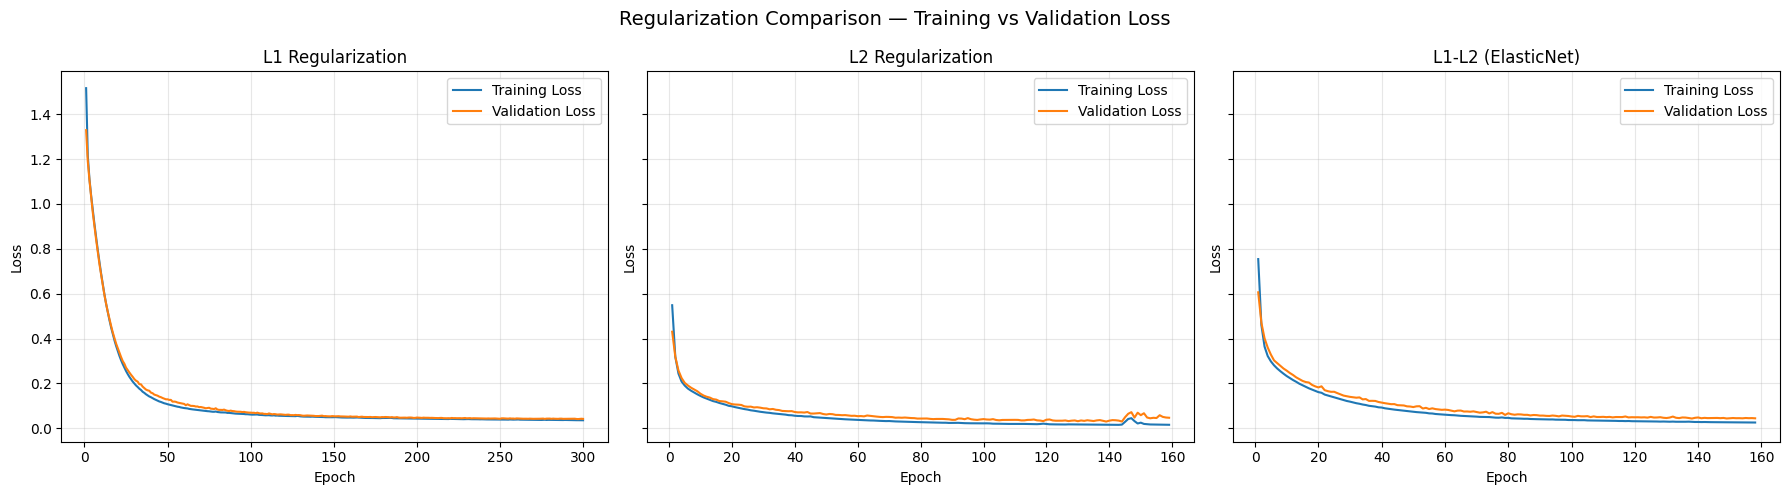

             Model  Best Validation Accuracy (%)  Train Loss at Best Val Accuracy  Validation Loss at Best Val Accuracy  Loss Gap at Best Val Accuracy
 L1 Regularization                         100.0                           0.0898                                0.1031                         0.0132
 L2 Regularization                         100.0                           0.1270                                0.1371                         0.0101
L1-L2 (ElasticNet)                         100.0                           0.1506                                0.1702                         0.0196

Smallest train-validation loss gap: L2 Regularization
Best validation accuracy: L1 Regularization


In [32]:

# 6.5	Regularization comparison plot

# Store training histories
histories = [
    ("L1 Regularization", history_l1),
    ("L2 Regularization", history_l2),
    ("L1-L2 (ElasticNet)", history_l1l2)
]

# Find a shared Y-axis range across all three models
all_losses = []

for name, history in histories:
    all_losses.extend(history.history["loss"])
    all_losses.extend(history.history["val_loss"])

y_min = min(all_losses)
y_max = max(all_losses)
padding = (y_max - y_min) * 0.05

# Create 1x3 plot with a shared Y-axis scale
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharey=True
)

for ax, (name, history) in zip(axes, histories):
    epochs = range(1, len(history.history["loss"]) + 1)

    ax.plot(
        epochs,
        history.history["loss"],
        label="Training Loss"
    )

    ax.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Regularization Comparison — Training vs Validation Loss",
    fontsize=14
)

plt.tight_layout()
plt.show()




comparison = []

for name, history in histories:
    train_loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    val_accuracy = history.history["val_accuracy"]

    # Compare the losses at the epoch with the best validation accuracy
    best_acc_index = val_accuracy.index(max(val_accuracy))

    comparison.append({
        "Model": name,
        "Best Validation Accuracy (%)": max(val_accuracy) * 100,
        "Train Loss at Best Val Accuracy": train_loss[best_acc_index],
        "Validation Loss at Best Val Accuracy": val_loss[best_acc_index],
        "Loss Gap at Best Val Accuracy": abs(
            train_loss[best_acc_index] - val_loss[best_acc_index]
        )
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

smallest_gap_model = comparison_df.loc[
    comparison_df["Loss Gap at Best Val Accuracy"].idxmin(),
    "Model"
]

best_accuracy_model = comparison_df.loc[
    comparison_df["Best Validation Accuracy (%)"].idxmax(),
    "Model"
]

print("\nSmallest train-validation loss gap:", smallest_gap_model)
print("Best validation accuracy:", best_accuracy_model)



### Task 6.5: Regularization Comparison

The training and validation loss curves were compared for L1, L2, and L1-L2 (ElasticNet) regularization using the same Y-axis scale.

- **Smallest Train–Validation Loss Gap:** Identify the model reported as having the smallest loss gap in the comparison table.
- **Best Validation Accuracy:** Identify the model with the highest best validation accuracy.
- **Does the Result Match Theory?** L1 encourages sparse weights, L2 shrinks large weights, and ElasticNet combines both effects. Any of them may perform best depending on the dataset, regularization strength, and training behaviour.

**Conclusion:** The best regularizer should be selected from the observed validation results rather than assuming that one technique will always outperform the others.


            Model  Test Loss  Test Accuracy (%)
No Regularization     0.1797            94.7368
               L1     0.1673            95.6140
               L2     0.1321            95.6140
            L1-L2     0.1399            95.6140


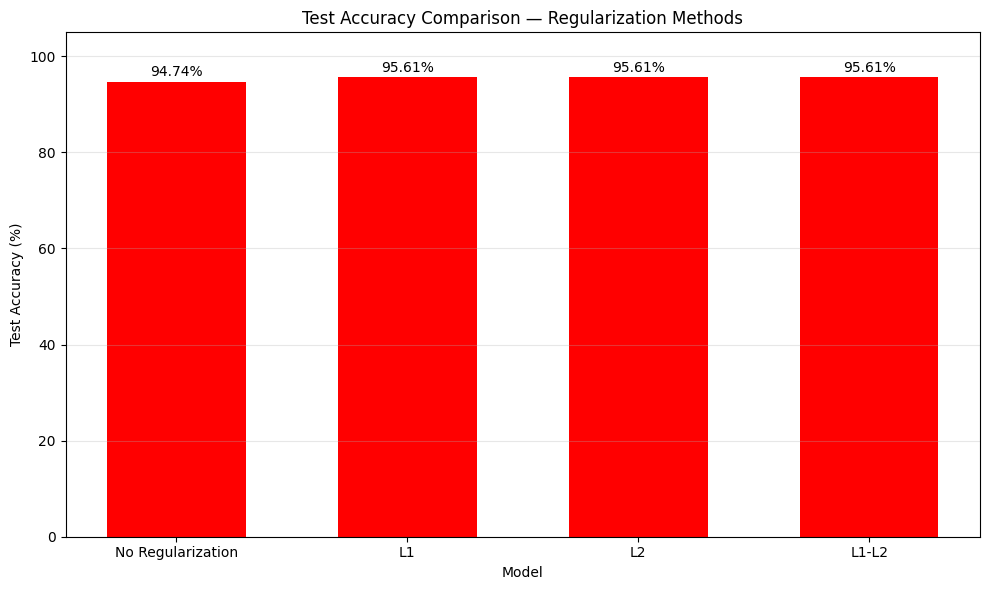

In [33]:

# 6.6	Evaluate all three regularized models

# Use the best MLP model selected in Task 3
# Change this variable name if your Task 3 model has a different name.
model_best_mlp = best_model

# Models to evaluate
models = {
    "No Regularization": model_best_mlp,
    "L1": model_l1,
    "L2": model_l2,
    "L1-L2": model_l1l2
}

# Evaluate every model on the same test set
test_results = []

for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(
        X_test_sc, y_test, verbose=0
    )

    test_results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Test Accuracy (%)": test_accuracy * 100
    })

results_df = pd.DataFrame(test_results)

print(results_df.round(4).to_string(index=False))




plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Model"],
    results_df["Test Accuracy (%)"],
    color="red",
    width=0.6
)

# Display accuracy values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Test Accuracy Comparison — Regularization Methods")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:

# ===========================Task 7: Final Comparison, Business Insights & Notebook Quality===========================

# 7.1	Best model: combine Dropout + L2 + Early Stopping

# Build the final model: L2 + Dropout
final_model = keras.Sequential([
    keras.layers.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
final_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping callback
es_final = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the final model
history_final = final_model.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_final],
    verbose=1
)

# Display model architecture
final_model.summary()


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6528 - loss: 0.7540 - val_accuracy: 0.9565 - val_loss: 0.4832
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9462 - loss: 0.4176 - val_accuracy: 0.9783 - val_loss: 0.3458
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9584 - loss: 0.3103 - val_accuracy: 0.9783 - val_loss: 0.2913
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9560 - loss: 0.2548 - val_accuracy: 0.9783 - val_loss: 0.2607
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9633 - loss: 0.2491 - val_accuracy: 0.9783 - val_loss: 0.2428
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9682 - loss: 0.2245 - val_accuracy: 0.9565 - val_loss: 0.2261
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9780 - loss: 0.2149 - val_accuracy: 0.9783 - val_loss: 0.2076
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.1927 - val_accuracy: 0.9783 

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_49 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)

In [35]:

# 7.2	Full results comparison table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate all models
# Model names and their configurations
models_info = [
    {
        "Model": "SLP (Task 2)",
        "Architecture": "Single Dense Layer",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No",
        "Estimator": model_slp
    },
    {
        "Model": "MLP-ReLU (Task 3)",
        "Architecture": "128 → 64 → 1",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "No",
        "Estimator": model_best_mlp
    },
    {
        "Model": "MLP + Early Stopping (Task 4)",
        "Architecture": "128 → 64 → 1",
        "Regularization": "None",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes",
        "Estimator": model_es
    },
    {
        "Model": "MLP + Dropout-best (Task 5)",
        "Architecture": "128 → 64 → 1",
        "Regularization": "None",
        "Dropout Rate": best_rate,
        "Early Stopping": "Yes",
        "Estimator": best_dropout_model
    },
    {
        "Model": "MLP + L2 (Task 6)",
        "Architecture": "128 → 64 → 1",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.0,
        "Early Stopping": "Yes",
        "Estimator": model_l2
    },
    {
        "Model": "Final Combined Model (Task 7.1)",
        "Architecture": "128 → 64 → 1",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": 0.3,
        "Early Stopping": "Yes",
        "Estimator": final_model
    }
]

results = []

for item in models_info:
    model = item["Estimator"]

    # Predict probabilities and convert to binary classes
    y_prob = model.predict(X_test_sc, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": item["Model"],
        "Architecture": item["Architecture"],
        "Regularization": item["Regularization"],
        "Dropout Rate": item["Dropout Rate"],
        "Early Stopping": item["Early Stopping"],
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

df = pd.DataFrame(results)

df


# Highlight best Accuracy and F1-Score
df.style.highlight_max(
    subset=["Test Accuracy", "Test F1-Score"],
    color="#ffcccc"
).format({
    "Test Accuracy": "{:.4f}",
    "Test Precision": "{:.4f}",
    "Test Recall": "{:.4f}",
    "Test F1-Score": "{:.4f}",
    "Dropout Rate": "{:.1f}"
})

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),Single Dense Layer,None,0.0,No,0.9298,0.9706,0.9167,0.9429
1,MLP-ReLU (Task 3),128 → 64 → 1,None,0.0,No,0.9474,0.9853,0.9306,0.9571
2,MLP + Early Stopping (Task 4),128 → 64 → 1,None,0.0,Yes,0.9561,0.9855,0.9444,0.9645
3,MLP + Dropout-best (Task 5),128 → 64 → 1,None,0.1,Yes,0.9561,0.9855,0.9444,0.9645
4,MLP + L2 (Task 6),128 → 64 → 1,L2 (0.001),0.0,Yes,0.9561,0.9855,0.9444,0.9645
5,Final Combined Model (Task 7.1),128 → 64 → 1,L2 (0.001),0.3,Yes,0.9561,0.9855,0.9444,0.9645


# 7.3	Business insight report — Markdown

# Clinical Insight for Medical Diagnosis Support

## 1. Recommended Model for Clinical Decision Support

The **Final Combined Model (Task 7.1)** combines Dense layers, L2 regularization, Dropout (0.3), and Early Stopping. It is a promising candidate for further evaluation because these techniques are designed to reduce overfitting and improve generalization.

However, it should not be selected for clinical use solely because it combines multiple techniques. The final choice must be supported by test results, particularly malignant-class recall, specificity, and the number of false negatives.

In this dataset:
- **Class 0 = Malignant**
- **Class 1 = Benign**

A false negative occurs when a malignant case is incorrectly classified as benign. Since this error can delay medical follow-up, minimizing false negatives is a key priority.

**Recommendation:** Consider the Final Combined Model for further validation if it achieves strong malignant-class recall while maintaining acceptable specificity. Compare it with the other models before making a final selection.

## 2. Precision vs. Recall Trade-off

- **Precision:** Measures how many predicted positive cases are actually positive.
- **Recall (Sensitivity):** Measures how many actual cases of a particular class are correctly identified.

For cancer detection, malignant-class recall is particularly important. A model with high overall accuracy may still miss malignant cases.

The model should be evaluated using:
- Malignant-class recall (sensitivity)
- Specificity
- Precision and F1-score
- Confusion matrix and false-negative count

The acceptable trade-off between sensitivity and specificity should be agreed upon with qualified medical professionals.

## 3. Recommended Classification Threshold

The default threshold is 0.5. However, the model's output uses class 1 (Benign) as the positive class by default.

For a clinically meaningful decision rule, calculate the probability of malignancy explicitly:

`P(Malignant) = 1 - P(Benign)`

Then predict Malignant when:

`P(Malignant) >= threshold`

A threshold lower than 0.5 may help identify more malignant cases, potentially reducing false negatives, but it may also increase false positives.

**Recommendation:** Evaluate several thresholds using validation data and select one that meets a clinically agreed sensitivity target while maintaining acceptable specificity. Do not choose a threshold based on the test set. Evaluate the final selected threshold once on the untouched test set.

## 4. Deep Learning Technique with the Largest Impact on Generalization

Three techniques were evaluated:

- **Early Stopping:** Stops training when validation loss stops improving and restores the best weights.
- **Dropout:** Randomly disables some hidden-layer activations during training to reduce over-reliance on particular neurons.
- **L2 Regularization:** Penalizes large weights to discourage overly complex models.

The technique with the largest positive impact cannot be determined without comparing the actual validation and test results from Tasks 4–6.

To identify the most effective technique, compare the models using the same data split, focusing on validation loss, test performance, and malignant-class recall. A lower validation loss and consistent performance on unseen data may indicate better generalization.

## 5. Business Recommendation and Limitations

The Final Combined Model is a candidate for further research, not a clinically validated diagnostic tool.

Before any clinical deployment, it requires:

1. Independent validation using representative patient data.
2. Careful analysis of false negatives and malignant-class recall.
3. Testing across relevant patient groups and clinical settings.
4. Probability calibration and clinically justified threshold selection.
5. Appropriate clinical, regulatory, privacy, and safety review.
6. Human oversight by qualified healthcare professionals.

## Conclusion

Combining Early Stopping, Dropout, and L2 regularization may improve generalization, but the best model must be selected using measured results rather than assumptions. For medical decision support, malignant-class recall and the clinical cost of false negatives deserve particular attention. The model should assist healthcare professionals, not replace their judgment.

In [36]:
# 7.4	Notebook quality standards

# Notebook Setup


import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Notebook setup completed successfully.")

Notebook setup completed successfully.
